# Agentic Fraud Alert Triage with Human-in-the-Loop

**Goal.** Fraud teams drown in alerts. Most anomaly-detector alerts are false positives, but every one needs a decision. This project builds an agent team that **investigates each alert, decides what it can safely decide, and routes the rest to a human analyst**, keeping a complete audit trail. The aim is to cut analyst workload without losing fraud catches.

| Agent / node | Type | Responsibility |
|---|---|---|
| **Detector** | Isolation Forest | Scores every transaction. The top 0.5% of the test period become alerts. |
| **Evidence collector** | Tools | Gathers the anomaly score, the most unusual features, the outcome of the most similar *historical* labelled cases (case-based retrieval), and the transaction's amount and time |
| **Risk router** | Rules on evidence | Clear cases go to auto-escalate or auto-dismiss; ambiguous cases go to the LLM investigator |
| **LLM investigator** | LLM, validated output | Reads the evidence and returns a structured decision, `escalate` or `dismiss`, with confidence and rationale |
| **Policy guard** | Hard rules | Overrides automation when stakes are high: no auto-dismissal above €500, and low-confidence LLM decisions go to a human |
| **Human analyst** | LangGraph `interrupt` | The workflow pauses and resumes with the analyst's decision. *In this notebook the analyst is simulated with the dataset's true labels.* |
| **Case reporter** | LLM / template | Writes a case note for escalated alerts; every decision is appended to a JSONL audit log |

**Evaluation.** All alerts from a later time period are processed. The agentic triage is compared with two baselines: an analyst reviewing every alert, and auto-escalating every alert. Metrics are frauds caught, false escalations, and the number of cases a human must review.

**Data.** The ULB / Worldline credit-card fraud dataset: 284,807 transactions, 492 frauds, PCA-anonymised with no personal information. Licence: ODbL (database) and DbCL (contents). It is downloaded at run time from a public GitHub mirror and checksum-verified.

## 1. Setup

In [1]:
import os
os.environ["TQDM_DISABLE"] = "1"   # keep notebook output readable
import hashlib, urllib.request, time, warnings, json, re
from pathlib import Path
from typing import Literal, Optional, TypedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import plotly.express as px
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
SEED = 42
DATA = Path("data"); DATA.mkdir(exist_ok=True)

### LLM backend

Every agent calls the language model through one small interface, so the notebook runs the same way with either backend:

* **OpenAI** (`gpt-4o-mini` by default) is used when `OPENAI_API_KEY` is set in the environment or in a `.env` file.
* **Offline:** otherwise, an open-weight model runs locally through Hugging Face Transformers: `Qwen/Qwen2.5-1.5B-Instruct` (Apache-2.0, about 3 GB, CPU-friendly). No key or paid API is needed.

Responses are cached on disk, keyed by a hash of the prompt, so re-running the notebook is fast and reproducible. Structured outputs are validated against Pydantic schemas, and the model is re-prompted with the validation error if a reply fails.

In [2]:
import ast, hashlib, json, logging, os, re, time
from pathlib import Path
from typing import Optional, Type

from dotenv import load_dotenv
from pydantic import BaseModel, ValidationError

load_dotenv()
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
_console = logging.StreamHandler()
_console.setLevel(logging.WARNING)   # full detail goes to outputs/run.log; the notebook shows warnings only
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s | %(message)s",
                    handlers=[logging.FileHandler(OUT / "run.log", mode="w"), _console], force=True)
for noisy in ("httpx", "httpx2", "httpcore", "urllib3", "filelock", "chromadb", "sentence_transformers", "transformers", "huggingface_hub"):
    logging.getLogger(noisy).setLevel(logging.WARNING)
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)   # silences the anonymous-download notice
log = logging.getLogger("agents")


class LLM:
    """Chat-completion wrapper: OpenAI if a key is configured, otherwise a local Hugging Face model."""

    def __init__(self, provider: str = "auto", local_model: str = "Qwen/Qwen2.5-1.5B-Instruct",
                 openai_model: Optional[str] = None, cache_path: Path = OUT / "llm_cache.json"):
        if provider == "auto":
            provider = "openai" if os.getenv("OPENAI_API_KEY") else "local"
        self.provider = provider
        self.cache_path = Path(cache_path)
        self.cache = json.loads(self.cache_path.read_text()) if self.cache_path.exists() else {}
        self.stats = {"calls": 0, "cache_hits": 0, "seconds": 0.0, "output_tokens": 0}
        if provider == "openai":
            from langchain_openai import ChatOpenAI
            self.model_name = openai_model or os.getenv("OPENAI_MODEL", "gpt-4o-mini")
            self._client = ChatOpenAI(model=self.model_name, temperature=0, timeout=60, max_retries=3)
        else:
            import torch
            from transformers import AutoModelForCausalLM, AutoTokenizer
            self.model_name = local_model
            torch.set_num_threads(max(1, os.cpu_count() or 1))
            self._tok = AutoTokenizer.from_pretrained(local_model)
            self._model = AutoModelForCausalLM.from_pretrained(local_model, dtype=torch.bfloat16).eval()
        log.info("LLM backend: %s (%s)", self.provider, self.model_name)

    def _key(self, messages, max_tokens):
        blob = json.dumps({"m": self.model_name, "msgs": messages, "max": max_tokens}, sort_keys=True)
        return hashlib.sha256(blob.encode()).hexdigest()

    def chat(self, messages: list, max_tokens: int = 256) -> str:
        key = self._key(messages, max_tokens)
        self.stats["calls"] += 1
        if key in self.cache:
            self.stats["cache_hits"] += 1
            return self.cache[key]
        t0 = time.time()
        if self.provider == "openai":
            from langchain_core.messages import AIMessage, HumanMessage, SystemMessage
            role = {"system": SystemMessage, "user": HumanMessage, "assistant": AIMessage}
            reply = self._client.invoke([role[m["role"]](m["content"]) for m in messages], max_tokens=max_tokens)
            text = reply.content
            n_out = (reply.usage_metadata or {}).get("output_tokens", 0)
        else:
            import torch
            enc = self._tok.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt", return_dict=True)
            with torch.no_grad():
                out = self._model.generate(**enc, max_new_tokens=max_tokens, do_sample=False,
                                           pad_token_id=self._tok.eos_token_id)
            new = out[0, enc["input_ids"].shape[1]:]
            text, n_out = self._tok.decode(new, skip_special_tokens=True), int(new.shape[0])
        dt = time.time() - t0
        self.stats["seconds"] += dt
        self.stats["output_tokens"] += n_out
        log.info("LLM call: %d output tokens in %.1fs", n_out, dt)
        self.cache[key] = text
        self.cache_path.write_text(json.dumps(self.cache))
        return text

    @staticmethod
    def extract_json(text: str):
        """Parse the first JSON object or array in a reply (models often wrap JSON in prose or code fences)."""
        text = re.sub(r"```(?:json)?", "", text)
        for opener, closer in (("{", "}"), ("[", "]")):
            start = text.find(opener)
            if start == -1:
                continue
            depth = 0
            for i in range(start, len(text)):
                depth += (text[i] == opener) - (text[i] == closer)
                if depth == 0:
                    chunk = text[start:i + 1]
                    try:
                        return json.loads(chunk)
                    except json.JSONDecodeError:
                        # small models often emit Python literals (None, True, single quotes); parse those safely
                        return ast.literal_eval(chunk)
        raise ValueError("no JSON found in model reply")

    def structured(self, messages: list, schema: Type[BaseModel], max_tokens: int = 256, retries: int = 2) -> BaseModel:
        """Ask for JSON matching `schema`; on failure, show the model the error and retry."""
        msgs = list(messages)
        last_err = None
        for attempt in range(retries + 1):
            reply = self.chat(msgs, max_tokens)
            try:
                return schema.model_validate(self.extract_json(reply))
            except (ValueError, ValidationError, json.JSONDecodeError) as e:
                last_err = e
                log.info("structured output invalid (attempt %d): %s", attempt + 1, str(e)[:200])
                msgs = msgs + [{"role": "assistant", "content": reply},
                               {"role": "user", "content": f"That reply was not valid JSON for the required schema ({str(e)[:200]}). Reply with only the corrected JSON."}]
        raise RuntimeError(f"structured output failed after {retries + 1} attempts: {last_err}")

In [3]:
llm = LLM()
print("Backend:", llm.provider, "|", llm.model_name)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Backend: local | Qwen/Qwen2.5-1.5B-Instruct


## 2. Data and detector

Splits follow time, as in production: the **historical** period (first 60%) trains the detector and supplies the labelled case library. The **live** period (last 40%) generates alerts.

In [4]:
DATA_URL = "https://raw.githubusercontent.com/stat432/credit-analysis/main/data-raw/creditcard.csv.zip"
DATA_SHA256 = "d9ade8e5a6c7b39cf3afef2de0fc10ecf9337c2cebdc6cc59a54b1d9dce007cc"
path = DATA / "creditcard.csv.zip"
if not path.exists():
    urllib.request.urlretrieve(DATA_URL, path)
assert hashlib.sha256(path.read_bytes()).hexdigest() == DATA_SHA256, "checksum mismatch"
df = pd.read_csv(path).sort_values("Time").reset_index(drop=True)
assert len(df) == 284_807 and df.Class.sum() == 492

FEATS = [f"V{i}" for i in range(1, 29)]
df["log_amount"] = np.log1p(df.Amount)
cut = int(0.6 * len(df))
hist, live = df.iloc[:cut].copy(), df.iloc[cut:].copy()
scaler = StandardScaler().fit(hist[FEATS + ["log_amount"]])
Xh, Xl = scaler.transform(hist[FEATS + ["log_amount"]]), scaler.transform(live[FEATS + ["log_amount"]])

iso = IsolationForest(n_estimators=300, max_samples=4096, random_state=SEED, n_jobs=-1).fit(Xh)
hist["anomaly"] = -iso.score_samples(Xh)
live["anomaly"] = -iso.score_samples(Xl)
ALERT_Q = 0.995
thr = np.quantile(hist.anomaly, ALERT_Q)          # threshold fixed on historical data
alerts = live[live.anomaly >= thr].copy()
print(f"historical: {len(hist):,} tx ({hist.Class.sum()} frauds) | live: {len(live):,} tx ({live.Class.sum()} frauds)")
print(f"alerts raised in live period: {len(alerts)} ({alerts.Class.sum()} frauds, precision {alerts.Class.mean():.1%}); "
      f"live frauds not alerted: {live.Class.sum() - alerts.Class.sum()}")

historical: 170,884 tx (360 frauds) | live: 113,923 tx (132 frauds)
alerts raised in live period: 530 (35 frauds, precision 6.6%); live frauds not alerted: 97


## 3. Evidence tools

* **Feature deviations:** the features with the largest absolute z-scores against normal historical behaviour.
* **Similar historical cases:** the 25 nearest labelled historical transactions in standardised feature space, and the share of them that were confirmed fraud. Fraud is rare, so neighbourhoods are drawn from a library that keeps every historical fraud plus a 20,000-transaction sample of normal ones, and the fraud share is reweighted back to base rates.
* **Context:** amount, hour of day and anomaly percentile.

In [5]:
rng = np.random.default_rng(SEED)
lib_idx = np.concatenate([np.where(hist.Class == 1)[0], rng.choice(np.where(hist.Class == 0)[0], 20000, replace=False)])
lib_X, lib_y = Xh[lib_idx], hist.Class.values[lib_idx]
normal_weight = (hist.Class == 0).sum() / 20000            # each sampled normal case stands for this many
knn = NearestNeighbors(n_neighbors=25).fit(lib_X)
normal_mu = Xh[hist.Class.values == 0].mean(0); normal_sd = Xh[hist.Class.values == 0].std(0)
FEAT_NAMES = FEATS + ["log_amount"]
hist_pct = np.sort(hist.anomaly.values)

def collect_evidence(row_idx: int) -> dict:
    x = Xl[live.index.get_loc(row_idx)]
    r = live.loc[row_idx]
    z = (x - normal_mu) / normal_sd
    top = np.argsort(-np.abs(z))[:4]
    dist, nb = knn.kneighbors(x[None, :])
    nb_y = lib_y[nb[0]]
    w = np.where(nb_y == 1, 1.0, normal_weight)
    return {"alert_id": int(row_idx), "amount_eur": round(float(r.Amount), 2), "hour": int((r.Time % 86400) // 3600),
            "anomaly_percentile": round(float(np.searchsorted(hist_pct, r.anomaly) / len(hist_pct) * 100), 2),
            "unusual_features": {FEAT_NAMES[i]: round(float(z[i]), 1) for i in top},
            "similar_cases_fraud_share": round(float((w * nb_y).sum() / w.sum()), 4),
            "similar_cases_fraud_count": int(nb_y.sum()), "similar_cases_n": int(len(nb_y))}

print(json.dumps(collect_evidence(alerts.index[0]), indent=1))

{
 "alert_id": 170937,
 "amount_eur": 152.65,
 "hour": 9,
 "anomaly_percentile": 99.58,
 "unusual_features": {
  "V1": -7.4,
  "V5": -7.3,
  "V3": -6.3,
  "V8": 6.0
 },
 "similar_cases_fraud_share": 0.0,
 "similar_cases_fraud_count": 0,
 "similar_cases_n": 25
}


## 4. Agents

### 4.1 Risk router and LLM investigator

Routing thresholds on the similar-case evidence are **set on historical alerts** (alerts the detector would have raised in the historical period), not on the live period being evaluated. Two explicit risk targets set the bands. Auto-dismissal is allowed only where the historical fraud rate was at most 0.5%; auto-escalation only where it was at least 50%. Everything in between goes to the LLM investigator.

In [6]:
hist_alerts = hist[hist.anomaly >= thr]
counts = []
for i in np.where(hist.anomaly.values >= thr)[0]:
    _, nb = knn.kneighbors(Xh[i][None, :], n_neighbors=26)
    nbr = [j for j in nb[0] if lib_idx[j] != i][:25]          # exclude the transaction itself from its own neighbourhood
    counts.append(int(lib_y[nbr].sum()))
hist_ev = pd.DataFrame({"fraud_count": counts, "y": hist_alerts.Class.values})
calib = hist_ev.groupby("fraud_count").y.agg(["count", "mean"])
print("Historical alerts: observed fraud rate by number of fraudulent neighbours (of 25)")
print(calib.round(3).T.to_string())
# Thresholds from explicit risk targets on HISTORICAL alerts:
#   auto-dismiss band  = counts <= LOW, where the cumulative historical fraud rate stays <= 0.5%
#   auto-escalate band = counts >= HIGH, where EVERY historical level at or above HIGH had a fraud rate >= 50%
MAX_DISMISS_RISK, MIN_ESCALATE_RATE = 0.005, 0.50
LOW = max(c for c in calib.index if hist_ev[hist_ev.fraud_count <= c].y.mean() <= MAX_DISMISS_RISK)
HIGH = min(c for c in calib.index if c > LOW and all(calib.loc[k, "mean"] >= MIN_ESCALATE_RATE for k in calib.index if k >= c))
print(f"auto-dismiss if <= {LOW} fraudulent neighbours (historical fraud rate {hist_ev[hist_ev.fraud_count <= LOW].y.mean():.2%}); "
      f"auto-escalate if >= {HIGH} (historical fraud rate {hist_ev[hist_ev.fraud_count >= HIGH].y.mean():.1%}); "
      f"investigate {LOW + 1}-{HIGH - 1} (historical fraud rate {hist_ev[hist_ev.fraud_count.between(LOW + 1, HIGH - 1)].y.mean():.1%})")

class Decision(BaseModel):
    decision: Literal["escalate", "dismiss"]
    confidence: float = Field(ge=0, le=1)
    rationale: str

INVESTIGATOR_SYSTEM = """You are a card-fraud investigator. Decide whether an alert should be ESCALATED (likely fraud) or DISMISSED (likely legitimate).
Weigh the evidence: similar_cases_fraud_count is how many of the 25 most similar historical transactions were confirmed fraud (strongest signal);
historical_fraud_rate_for_alerts_like_this is the calibrated share of past alerts with the same evidence that were fraud (escalate if it is high, dismiss if it is low);
every alert is already highly anomalous, so anomaly_percentile alone does not indicate fraud; unusual_features are z-scores of anonymised features (|z| > 5 is extreme).
Reply with JSON only: {"decision": "escalate" or "dismiss", "confidence": 0-1, "rationale": "<one sentence citing the evidence>"}"""

def calibrated_rate(count: int) -> float:
    """Historical fraud rate for alerts with this many fraudulent neighbours (pooled over the investigate band when sparse)."""
    if count in calib.index and calib.loc[count, "count"] >= 20:
        return float(calib.loc[count, "mean"])
    band = hist_ev[hist_ev.fraud_count.between(LOW + 1, HIGH - 1)]
    return float(band.y.mean())

def investigate(ev: dict) -> Decision:
    ev = {**ev, "historical_fraud_rate_for_alerts_like_this": round(calibrated_rate(ev["similar_cases_fraud_count"]), 3)}
    msgs = [{"role": "system", "content": INVESTIGATOR_SYSTEM}, {"role": "user", "content": json.dumps(ev)}]
    return llm.structured(msgs, Decision, max_tokens=120)

Historical alerts: observed fraud rate by number of fraudulent neighbours (of 25)
fraud_count       0      1     2    3      4    5    7    8    12   15   17   18   22   23     24       25
count        398.000  129.0  56.0  4.0  3.000  5.0  7.0  6.0  1.0  1.0  1.0  2.0  1.0  1.0  93.00  147.000
mean           0.003    0.0   0.0  0.0  0.667  0.2  0.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0   0.72    0.905
auto-dismiss if <= 3 fraudulent neighbours (historical fraud rate 0.17%); auto-escalate if >= 8 (historical fraud rate 84.2%); investigate 4-7 (historical fraud rate 20.0%)


### 4.2 Policy guard, human interrupt and audit log

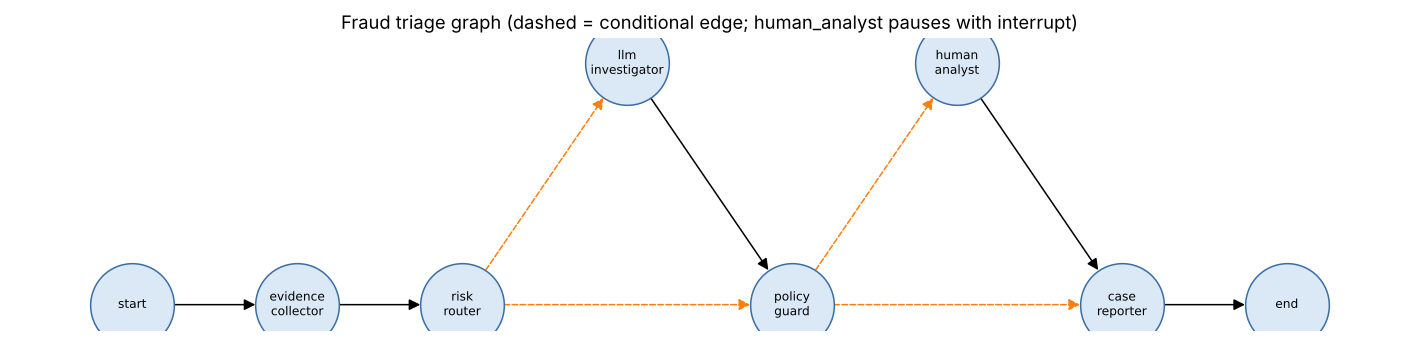

In [7]:
AUTO_DISMISS_MAX_AMOUNT = 500.0
MIN_LLM_CONFIDENCE = 0.6
AUDIT = OUT / "audit_log.jsonl"
AUDIT.write_text("")

def audit(record: dict):
    with AUDIT.open("a") as f:
        f.write(json.dumps(record) + "\n")


class TriageState(TypedDict, total=False):
    alert_id: int
    evidence: dict
    route: str
    proposal: Optional[dict]
    decision: str
    decided_by: str
    policy_notes: list
    case_note: str

def evidence_node(s):
    return {"evidence": collect_evidence(s["alert_id"]), "policy_notes": []}

def router_node(s):
    c = s["evidence"]["similar_cases_fraud_count"]
    route = "auto_escalate" if c >= HIGH else ("auto_dismiss" if c <= LOW else "investigate")
    return {"route": route}

def investigator_node(s):
    try:
        d = investigate(s["evidence"])
        return {"proposal": d.model_dump()}
    except RuntimeError as e:
        return {"proposal": {"decision": "escalate", "confidence": 0.0, "rationale": f"investigator failed: {e}"}}

def policy_node(s):
    ev, notes = s["evidence"], list(s["policy_notes"])
    if s["route"] == "auto_escalate":
        return {"decision": "escalate", "decided_by": "rules", "policy_notes": notes}
    if s["route"] == "auto_dismiss":
        if ev["amount_eur"] > AUTO_DISMISS_MAX_AMOUNT:
            notes.append(f"amount {ev['amount_eur']} > {AUTO_DISMISS_MAX_AMOUNT}: auto-dismissal not permitted")
            return {"decision": "needs_human", "policy_notes": notes}
        return {"decision": "dismiss", "decided_by": "rules", "policy_notes": notes}
    p = s["proposal"]
    if p["confidence"] < MIN_LLM_CONFIDENCE:
        notes.append(f"LLM confidence {p['confidence']:.2f} < {MIN_LLM_CONFIDENCE}")
        return {"decision": "needs_human", "policy_notes": notes}
    if p["decision"] == "dismiss" and ev["amount_eur"] > AUTO_DISMISS_MAX_AMOUNT:
        notes.append(f"LLM proposed dismissal of a {ev['amount_eur']} EUR transaction: requires human sign-off")
        return {"decision": "needs_human", "policy_notes": notes}
    return {"decision": p["decision"], "decided_by": "llm_investigator", "policy_notes": notes}

def human_node(s):
    # Pauses the graph. The caller resumes with Command(resume={"decision": ..., "analyst": ...}).
    answer = interrupt({"alert_id": s["alert_id"], "evidence": s["evidence"], "proposal": s.get("proposal"), "policy_notes": s["policy_notes"]})
    return {"decision": answer["decision"], "decided_by": f"human:{answer.get('analyst', 'analyst')}"}

def reporter_node(s):
    ev = s["evidence"]
    note = (f"Alert {ev['alert_id']}: {s['decision'].upper()} by {s['decided_by']}. Amount {ev['amount_eur']} EUR at hour {ev['hour']}; "
            f"anomaly percentile {ev['anomaly_percentile']}; {ev['similar_cases_fraud_count']}/25 similar historical cases were fraud; "
            f"most unusual features {ev['unusual_features']}."
            + (f" Investigator: {s['proposal']['rationale']}" if s.get("proposal") else "")
            + (f" Policy: {'; '.join(s['policy_notes'])}" if s["policy_notes"] else ""))
    audit({"ts": time.time(), "alert_id": ev["alert_id"], "route": s["route"], "decision": s["decision"], "decided_by": s["decided_by"],
           "proposal": s.get("proposal"), "policy_notes": s["policy_notes"], "evidence": ev})
    return {"case_note": note}

g = StateGraph(TriageState)
for n, fn in [("evidence_collector", evidence_node), ("risk_router", router_node), ("llm_investigator", investigator_node),
              ("policy_guard", policy_node), ("human_analyst", human_node), ("case_reporter", reporter_node)]:
    g.add_node(n, fn)
g.set_entry_point("evidence_collector")
g.add_edge("evidence_collector", "risk_router")
g.add_conditional_edges("risk_router", lambda s: "investigate" if s["route"] == "investigate" else "policy",
                        {"investigate": "llm_investigator", "policy": "policy_guard"})
g.add_edge("llm_investigator", "policy_guard")
g.add_conditional_edges("policy_guard", lambda s: "human" if s["decision"] == "needs_human" else "report",
                        {"human": "human_analyst", "report": "case_reporter"})
g.add_edge("human_analyst", "case_reporter")
g.add_edge("case_reporter", END)
triage = g.compile(checkpointer=MemorySaver())

G = triage.get_graph()
nxg = nx.DiGraph([(e.source, e.target, {"c": e.conditional}) for e in G.edges])
pos = {"__start__": (0, 0), "evidence_collector": (1, 0), "risk_router": (2, 0), "llm_investigator": (3, 0.6), "policy_guard": (4, 0),
       "human_analyst": (5, 0.6), "case_reporter": (6, 0), "__end__": (7, 0)}
fig, ax = plt.subplots(figsize=(13, 3.2))
nx.draw_networkx_nodes(nxg, pos, node_color="#dbe9f6", node_size=3000, edgecolors="#3a6ea5", ax=ax)
nx.draw_networkx_labels(nxg, pos, labels={n: n.replace("_", "\n") for n in nxg}, font_size=8, ax=ax)
for c, st, col in [(False, "solid", "k"), (True, "dashed", "tab:orange")]:
    nx.draw_networkx_edges(nxg, pos, edgelist=[(u, v) for u, v, d in nxg.edges(data=True) if d["c"] == c], style=st, edge_color=col,
                           arrows=True, arrowsize=15, node_size=3000, ax=ax)
ax.set_title("Fraud triage graph (dashed = conditional edge; human_analyst pauses with interrupt)"); ax.axis("off"); plt.tight_layout(); plt.show()

## 5. Human-in-the-loop demonstration

One alert is run step by step. When the policy guard routes it to a human, the graph **pauses** and returns the case packet an analyst would see. The run then resumes with the analyst's decision. The thread's state is held by the checkpointer, so in production the pause could last minutes or days.

In [8]:
def simulated_analyst(alert_id: int) -> dict:
    """Stands in for a human reviewer. Uses the true label, i.e. assumes a perfect analyst. Clearly a simulation."""
    return {"decision": "escalate" if live.loc[alert_id, "Class"] == 1 else "dismiss", "analyst": "simulated"}

def process(alert_id: int, verbose: bool = False) -> dict:
    cfg = {"configurable": {"thread_id": f"alert-{alert_id}"}}
    out = triage.invoke({"alert_id": int(alert_id)}, cfg)
    paused = "__interrupt__" in out
    if paused:
        packet = out["__interrupt__"][0].value
        if verbose:
            print("PAUSED for human review. Case packet:\n", json.dumps(packet, indent=1)[:900])
        out = triage.invoke(Command(resume=simulated_analyst(alert_id)), cfg)
    state = triage.get_state(cfg).values
    return {"alert_id": int(alert_id), "route": state["route"], "decision": state["decision"], "decided_by": state["decided_by"],
            "human": paused, "llm_used": state.get("proposal") is not None, "case_note": state["case_note"]}

# pick an alert that will need a human: a large amount among the ambiguous ones
ev_all = {i: collect_evidence(i) for i in alerts.index}
demo_id = next(i for i, e in ev_all.items() if e["amount_eur"] > AUTO_DISMISS_MAX_AMOUNT and e["similar_cases_fraud_count"] <= LOW) \
          if any(e["amount_eur"] > AUTO_DISMISS_MAX_AMOUNT and e["similar_cases_fraud_count"] <= LOW for e in ev_all.values()) else alerts.index[0]
r = process(demo_id, verbose=True)
print("\nRESUMED ->", r["decision"], "by", r["decided_by"]); print(r["case_note"])
AUDIT.write_text("")   # the full evaluation below starts with a fresh audit log

PAUSED for human review. Case packet:
 {
 "alert_id": 171191,
 "evidence": {
  "alert_id": 171191,
  "amount_eur": 1746.0,
  "hour": 9,
  "anomaly_percentile": 99.72,
  "unusual_features": {
   "V21": 11.3,
   "V8": -8.6,
   "V6": 8.5,
   "V20": -6.3
  },
  "similar_cases_fraud_share": 0.0,
  "similar_cases_fraud_count": 0,
  "similar_cases_n": 25
 },
 "proposal": null,
 "policy_notes": [
  "amount 1746.0 > 500.0: auto-dismissal not permitted"
 ]
}

RESUMED -> dismiss by human:simulated
Alert 171191: DISMISS by human:simulated. Amount 1746.0 EUR at hour 9; anomaly percentile 99.72; 0/25 similar historical cases were fraud; most unusual features {'V21': 11.3, 'V8': -8.6, 'V6': 8.5, 'V20': -6.3}. Policy: amount 1746.0 > 500.0: auto-dismissal not permitted


0

## 6. Process every live alert

In [9]:
route_counts = pd.Series({i: ("auto_escalate" if e["similar_cases_fraud_count"] >= HIGH else "auto_dismiss" if e["similar_cases_fraud_count"] <= LOW else "investigate")
                          for i, e in ev_all.items()}).value_counts()
print("Routing of", len(alerts), "alerts:", route_counts.to_dict())
t0 = time.time()
results = pd.DataFrame([process(i) for i in alerts.index])
results["fraud"] = live.loc[results.alert_id, "Class"].values
print(f"processed {len(results)} alerts in {time.time() - t0:.0f}s; LLM investigated {results.llm_used.sum()}, humans reviewed {results.human.sum()}")

Routing of 530 alerts: {'auto_dismiss': 491, 'auto_escalate': 36, 'investigate': 3}


processed 530 alerts in 4s; LLM investigated 3, humans reviewed 178


## 7. Evaluation

In [10]:
n_alerts, n_fraud = len(results), int(results.fraud.sum())
esc = results.decision == "escalate"
def row(name, escalated, human_reviews):
    tp = int((escalated & (results.fraud == 1)).sum())
    return {"policy": name, "frauds caught": f"{tp}/{n_fraud}", "recall": tp / n_fraud, "false escalations": int((escalated & (results.fraud == 0)).sum()),
            "precision of escalations": tp / max(1, int(escalated.sum())), "human reviews": human_reviews, "workload vs review-all": human_reviews / n_alerts}
comparison = pd.DataFrame([
    row("Analyst reviews every alert", results.fraud == 1, n_alerts),
    row("Auto-escalate every alert (no review)", pd.Series(True, index=results.index), 0),
    row("Agentic triage (this notebook)", esc, int(results.human.sum())),
]).set_index("policy")
comparison.style.format({"recall": "{:.1%}", "precision of escalations": "{:.1%}", "workload vs review-all": "{:.0%}"})

,frauds caught,recall,false escalations,precision of escalations,human reviews,workload vs review-all
policy,,,,,,
Analyst reviews every alert,35/35,100.0%,0,100.0%,530,100%
Auto-escalate every alert (no review),35/35,100.0%,495,6.6%,0,0%
Agentic triage (this notebook),35/35,100.0%,1,97.2%,178,34%


In [11]:
by_actor = results.groupby("decided_by").apply(lambda d: pd.Series({
    "cases": len(d), "frauds": int(d.fraud.sum()), "escalated": int((d.decision == "escalate").sum()),
    "correct": int(((d.decision == "escalate") == (d.fraud == 1)).sum())}), include_groups=False)
by_actor["accuracy"] = by_actor.correct / by_actor.cases
print("Final decisions by actor (accuracy against true labels):")
display(by_actor)
# The LLM's proposals are scored separately: the policy guard may route a correct proposal to a human anyway.
props = [json.loads(l) for l in AUDIT.read_text().splitlines()]
props = [r for r in props if r["proposal"]]
if props:
    ok = [(r["proposal"]["decision"] == "escalate") == bool(live.loc[r["alert_id"], "Class"]) for r in props]
    sent_to_human = sum(r["decided_by"].startswith("human") for r in props)
    print(f"LLM investigator proposals: {sum(ok)}/{len(ok)} correct; {sent_to_human} of {len(ok)} were sent to a human by the policy guard "
          f"(confidence below {MIN_LLM_CONFIDENCE} or dismissal above EUR {AUTO_DISMISS_MAX_AMOUNT:.0f}).")

Final decisions by actor (accuracy against true labels):


,cases,frauds,escalated,correct,accuracy
decided_by,,,,,
human:simulated,178,0,0,178,1.000000
rules,352,35,36,351,0.997159


LLM investigator proposals: 3/3 correct; 3 of 3 were sent to a human by the policy guard (confidence below 0.6 or dismissal above EUR 500).


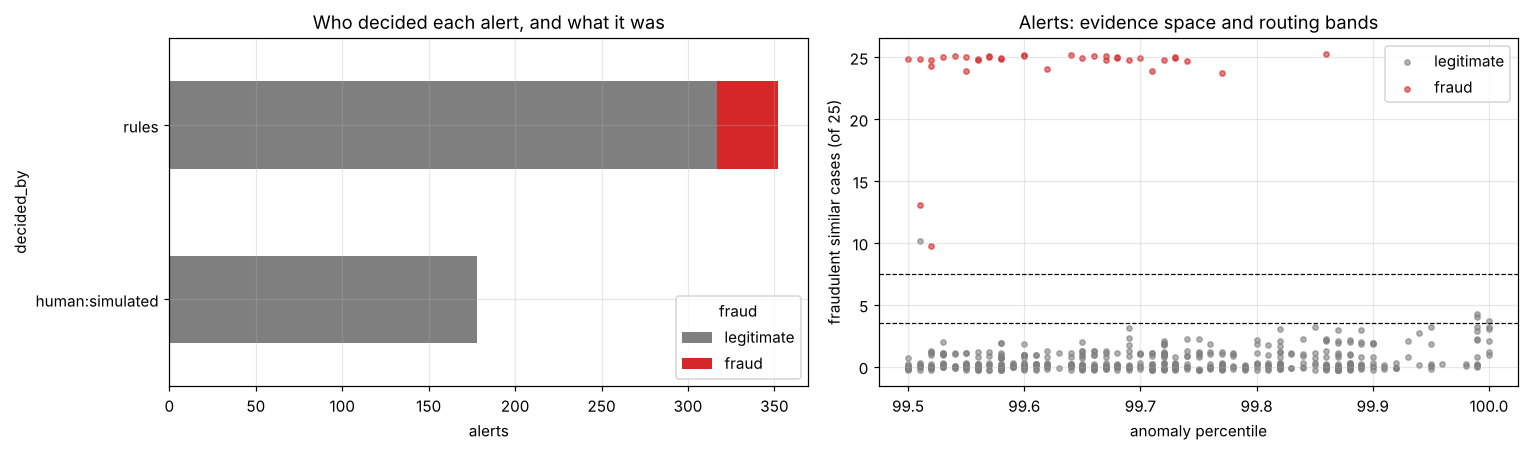

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
mix = results.groupby(["decided_by", "fraud"]).size().unstack(fill_value=0).rename(columns={0: "legitimate", 1: "fraud"})
mix.plot.barh(stacked=True, ax=axes[0], color=["tab:gray", "tab:red"])
axes[0].set(title="Who decided each alert, and what it was", xlabel="alerts")
evdf = pd.DataFrame(ev_all.values())
evdf["fraud"] = live.loc[evdf.alert_id, "Class"].values
for lab, c in [(0, "tab:gray"), (1, "tab:red")]:
    d = evdf[evdf.fraud == lab]
    axes[1].scatter(d.anomaly_percentile, d.similar_cases_fraud_count + np.random.uniform(-0.3, 0.3, len(d)), s=12, c=c, alpha=0.6,
                    label="fraud" if lab else "legitimate")
axes[1].axhline(HIGH - 0.5, ls="--", c="k", lw=0.8); axes[1].axhline(LOW + 0.5, ls="--", c="k", lw=0.8)
axes[1].set(title="Alerts: evidence space and routing bands", xlabel="anomaly percentile", ylabel="fraudulent similar cases (of 25)")
axes[1].legend(); plt.tight_layout(); plt.show()
px.scatter(evdf, x="anomaly_percentile", y="similar_cases_fraud_count", color=evdf.fraud.map({0: "legitimate", 1: "fraud"}),
           hover_data=["alert_id", "amount_eur", "hour"], title="Alert evidence (interactive)").write_html(OUT / "alerts.html", include_plotlyjs="cdn")

### Audit trail

Every alert produces one JSON line with the evidence, the route, any LLM proposal, policy notes, and who made the final decision. That is the record a model-risk or compliance review would ask for.

In [13]:
log_lines = AUDIT.read_text().splitlines()
print(len(log_lines), "audit records; example:")
example = next((l for l in log_lines if '"proposal": {' in l), log_lines[0])   # prefer a case the LLM investigated
print(json.dumps(json.loads(example), indent=1)[:1200])

530 audit records; example:
{
 "ts": 1795511762.9279335,
 "alert_id": 173054,
 "route": "investigate",
 "decision": "dismiss",
 "decided_by": "human:simulated",
 "proposal": {
  "decision": "dismiss",
  "confidence": 0.9,
  "rationale": "The alert has a very low similarity to known fraudulent cases (similarity count of 4 out of 25), and the historical fraud rate for similar alerts is also low at 0.2%. The alert's amount is relatively small compared to its percentile ranking, suggesting it may be a false positive."
 },
 "policy_notes": [
  "LLM proposed dismissal of a 4543.64 EUR transaction: requires human sign-off"
 ],
 "evidence": {
  "alert_id": 173054,
  "amount_eur": 4543.64,
  "hour": 9,
  "anomaly_percentile": 99.99,
  "unusual_features": {
   "V23": -31.7,
   "V20": -28.4,
   "V7": 16.5,
   "V2": -12.5
  },
  "similar_cases_fraud_share": 0.0219,
  "similar_cases_fraud_count": 4,
  "similar_cases_n": 25
 }
}


## 8. Discussion

* **Workload.** Clear-cut alerts, the large majority, are settled by rules on strong evidence. Humans see only the cases that policy says need a person (high value or low confidence), so analyst workload drops sharply compared with reviewing everything.
* **Catch rate.** The comparison table shows how many of the alerted frauds the triage keeps. Any fraud the automation dismisses is a real cost and is visible in the table; the routing thresholds trade workload against that risk and should be set with the fraud team's cost of a miss.
* **Role of the LLM.** The language model handles only the ambiguous middle band, and always under the policy guard: it can never auto-dismiss a high-value case. Its accuracy is reported separately, so its contribution can be judged on its own.
* **Simulated analyst.** Human decisions here use the true labels, which assumes a perfect analyst. In practice, human accuracy is below 100%, so the "human reviews" rows are an upper bound.

**Limitations.** The thresholds come from one historical window of two days of 2013 data. Detector misses (frauds never alerted) are outside triage and are reported separately above. A production system would add case-management integration, analyst feedback that retrains the evidence models, and monitoring for drift.

In [14]:
print(f"Backend: {llm.provider} ({llm.model_name}); {llm.stats['calls']} LLM calls ({llm.stats['cache_hits']} cached), {llm.stats['seconds']:.0f}s generation")

Backend: local (Qwen/Qwen2.5-1.5B-Instruct); 3 LLM calls (3 cached), 0s generation
